# Semantic Network and Inheritance

## Aim
To design and implement a semantic network using a graph library, represent **IS-A** and **HAS-A** relationships, support inherited properties, answer reachability queries, dynamically add nodes, and visualize the network.

## Problem Overview
A semantic network represents knowledge as a graph:
- **Nodes** represent concepts or entities.
- **Directed edges** represent relationships between concepts.
- **IS-A** represents class/subclass relationships.
- **HAS-A** represents properties or components associated with a concept.

The network in this practical uses animals and vehicles. It answers questions such as:
- Does a Penguin have wings?
- Is a Car a Vehicle?

## Learning Objectives
1. Represent concepts and relationships in a directed graph.
2. Distinguish IS-A relationships from HAS-A relationships.
3. Implement recursive inheritance traversal.
4. Perform IS-A reachability queries.
5. Add nodes and relationships dynamically.
6. Visualize the semantic network.

## 1. Import Required Libraries

NetworkX is used to create and traverse the graph. Matplotlib is used to visualize it.

If you are using Google Colab, run the installation cell below.

In [1]:
!pip -q install networkx matplotlib

import networkx as nx
import matplotlib.pyplot as plt

print("NetworkX version:", nx.__version__)
print("Libraries imported successfully.")

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

NetworkX version: 3.6.1
Libraries imported successfully.


## 2. Create the Semantic Network

A directed graph (`DiGraph`) stores concepts as nodes and relationships as directed edges. Each edge has a `relation` attribute that identifies whether it is an **IS-A** or **HAS-A** relationship.

In [2]:
G = nx.DiGraph()

# IS-A relationships: subclass -> superclass
G.add_edge("Penguin", "Bird", relation="IS-A")
G.add_edge("Bird", "Animal", relation="IS-A")
G.add_edge("Eagle", "Bird", relation="IS-A")
G.add_edge("Car", "Vehicle", relation="IS-A")

# HAS-A relationships: concept -> property/component
G.add_edge("Bird", "Wings", relation="HAS-A")
G.add_edge("Animal", "Cells", relation="HAS-A")
G.add_edge("Car", "Engine", relation="HAS-A")
G.add_edge("Car", "Wheels", relation="HAS-A")

print("Nodes in the semantic network:")
print(sorted(G.nodes()))

print("\nRelationships:")
for source, target, data in G.edges(data=True):
    print(f"{source} --{data['relation']}--> {target}")

Nodes in the semantic network:
['Animal', 'Bird', 'Car', 'Cells', 'Eagle', 'Engine', 'Penguin', 'Vehicle', 'Wheels', 'Wings']

Relationships:
Penguin --IS-A--> Bird
Bird --IS-A--> Animal
Bird --HAS-A--> Wings
Animal --HAS-A--> Cells
Eagle --IS-A--> Bird
Car --IS-A--> Vehicle
Car --HAS-A--> Engine
Car --HAS-A--> Wheels


## 3. Implement Inheritance

A concept inherits HAS-A properties from its parent concepts through IS-A edges.

For example:
- Penguin IS-A Bird.
- Bird IS-A Animal.
- Bird HAS-A Wings.
- Animal HAS-A Cells.

Therefore, Penguin inherits Wings and Cells.

The traversal follows only IS-A edges when moving to parent concepts. This prevents a HAS-A edge from being mistaken for an inheritance relationship.

In [3]:
def get_inherited_properties(graph, node):
    """Return direct and inherited HAS-A properties for a concept."""
    if node not in graph:
        raise ValueError(f"Concept '{node}' is not present in the network.")

    properties = set()
    visited = set()

    def traverse(current):
        if current in visited:
            return
        visited.add(current)

        for successor in graph.successors(current):
            relation = graph[current][successor].get("relation")

            if relation == "HAS-A":
                properties.add(successor)
            elif relation == "IS-A":
                traverse(successor)

    traverse(node)
    return properties


penguin_properties = get_inherited_properties(G, "Penguin")
print("Properties inherited by Penguin:", sorted(penguin_properties))

Properties inherited by Penguin: ['Cells', 'Wings']


## 4. Query: Does a Penguin Have Wings?

The query checks whether `Wings` is present in the properties inherited by `Penguin`.

In [4]:
properties = get_inherited_properties(G, "Penguin")

if "Wings" in properties:
    print("Yes, Penguin has wings.")
else:
    print("No, Penguin does not have wings.")

Yes, Penguin has wings.


## 5. IS-A Reachability Query

An IS-A query must traverse **only IS-A edges**. A general graph path is not sufficient because it could include HAS-A relationships.

The function below builds a temporary graph containing only IS-A edges and checks whether a directed path exists from the child concept to the parent concept.

In [5]:
def is_a(graph, child, parent):
    """Check whether child is parent or is connected to parent by IS-A edges."""
    if child not in graph or parent not in graph:
        return False

    if child == parent:
        return True

    isa_graph = nx.DiGraph()
    isa_graph.add_nodes_from(graph.nodes())

    isa_edges = [
        (source, target)
        for source, target, data in graph.edges(data=True)
        if data.get("relation") == "IS-A"
    ]
    isa_graph.add_edges_from(isa_edges)

    return nx.has_path(isa_graph, child, parent)


print("Is Car a Vehicle?", is_a(G, "Car", "Vehicle"))
print("Is Penguin an Animal?", is_a(G, "Penguin", "Animal"))
print("Is Penguin a Vehicle?", is_a(G, "Penguin", "Vehicle"))
print("Is Car an Engine?", is_a(G, "Car", "Engine"))

Is Car a Vehicle? True
Is Penguin an Animal? True
Is Penguin a Vehicle? False
Is Car an Engine? False


## 6. Dynamically Add Nodes and Relationships

New concepts can be added while the program is running. NetworkX automatically creates nodes when an edge is added, but this practical explicitly validates the relationship type before adding it.

In [6]:
VALID_RELATIONS = {"IS-A", "HAS-A"}

def add_relationship(graph, source, target, relation):
    if relation not in VALID_RELATIONS:
        raise ValueError("Relationship must be either 'IS-A' or 'HAS-A'.")

    if source == target:
        raise ValueError("A concept cannot be related to itself in this example.")

    graph.add_edge(source, target, relation=relation)
    print(f"Added: {source} --{relation}--> {target}")


add_relationship(G, "Sparrow", "Bird", "IS-A")
add_relationship(G, "Bird", "Feathers", "HAS-A")

print("\nSparrow inherited properties:")
print(sorted(get_inherited_properties(G, "Sparrow")))

Added: Sparrow --IS-A--> Bird
Added: Bird --HAS-A--> Feathers

Sparrow inherited properties:
['Cells', 'Feathers', 'Wings']


## 7. Visualize the Semantic Network

The graph uses separate edge styles and labels to distinguish relationship types:
- Solid arrows represent **IS-A**.
- Dashed arrows represent **HAS-A**.

This makes the semantic structure easier to interpret.

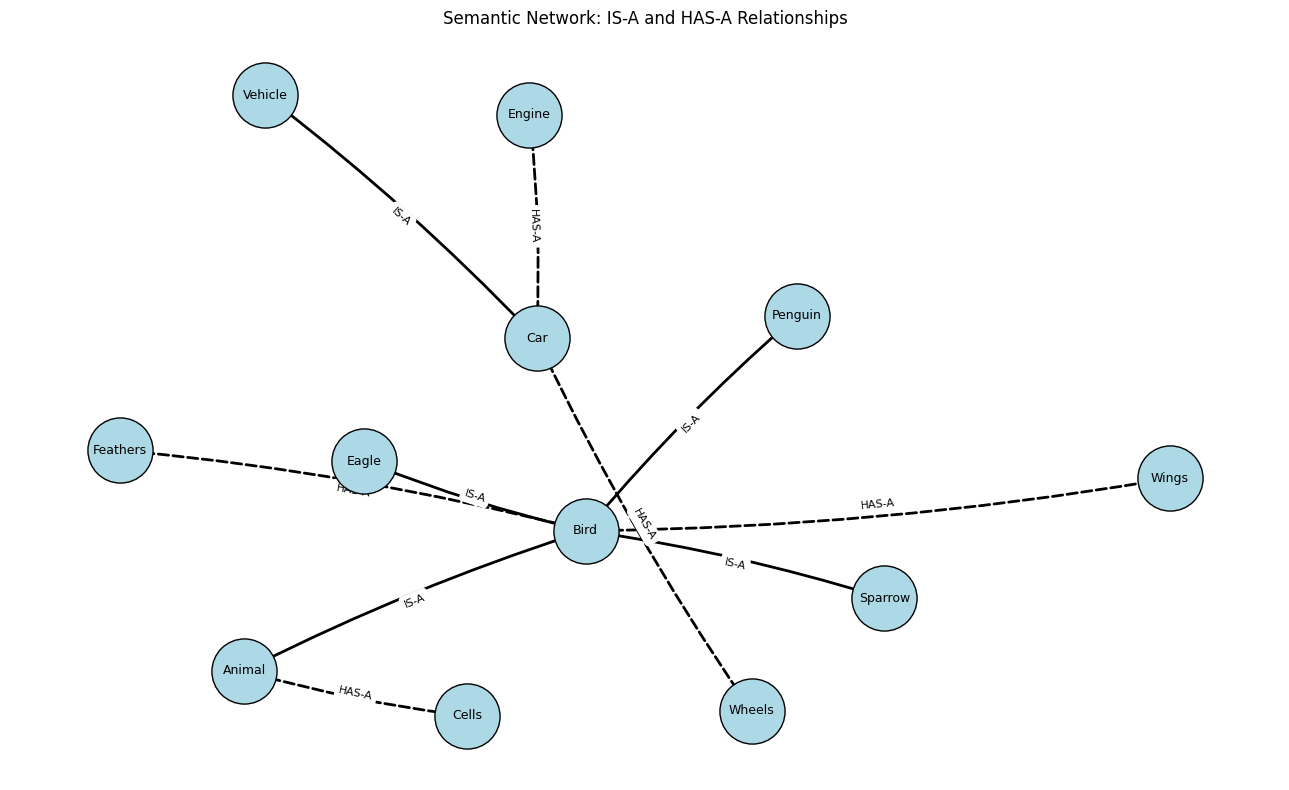

In [7]:
def visualize_semantic_network(graph):
    plt.figure(figsize=(13, 8))
    pos = nx.spring_layout(graph, seed=42, k=0.9)

    nx.draw_networkx_nodes(
        graph, pos,
        node_size=2200,
        node_color="lightblue",
        edgecolors="black"
    )
    nx.draw_networkx_labels(graph, pos, font_size=9)

    isa_edges = [
        (u, v) for u, v, d in graph.edges(data=True)
        if d.get("relation") == "IS-A"
    ]
    hasa_edges = [
        (u, v) for u, v, d in graph.edges(data=True)
        if d.get("relation") == "HAS-A"
    ]

    nx.draw_networkx_edges(
        graph, pos, edgelist=isa_edges,
        arrows=True, arrowstyle="-|>", arrowsize=18,
        width=2, style="solid", connectionstyle="arc3,rad=0.04"
    )
    nx.draw_networkx_edges(
        graph, pos, edgelist=hasa_edges,
        arrows=True, arrowstyle="-|>", arrowsize=18,
        width=2, style="dashed", connectionstyle="arc3,rad=0.04"
    )

    edge_labels = {
        (u, v): data["relation"]
        for u, v, data in graph.edges(data=True)
    }
    nx.draw_networkx_edge_labels(
        graph, pos, edge_labels=edge_labels, font_size=8,
        label_pos=0.5
    )

    plt.title("Semantic Network: IS-A and HAS-A Relationships")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


visualize_semantic_network(G)

## 8. Additional Queries and Verification

The following checks verify that:
1. Penguin inherits Wings from Bird.
2. Penguin inherits Cells from Animal through Bird.
3. Car is a Vehicle through an IS-A relationship.
4. A HAS-A relationship is not treated as an IS-A relationship.
5. Sparrow inherits properties from Bird and Animal.

In [8]:
assert "Wings" in get_inherited_properties(G, "Penguin")
assert "Cells" in get_inherited_properties(G, "Penguin")
assert is_a(G, "Car", "Vehicle")
assert is_a(G, "Penguin", "Animal")
assert not is_a(G, "Car", "Engine")
assert "Feathers" in get_inherited_properties(G, "Sparrow")

print("All semantic network verification tests passed.")

All semantic network verification tests passed.


## Observations

1. A semantic network represents knowledge through concepts and relationships.
2. IS-A relationships establish class hierarchies.
3. HAS-A relationships represent properties or components.
4. Recursive traversal allows a concept to inherit properties from multiple levels of its hierarchy.
5. Restricting inheritance traversal to IS-A edges avoids treating properties as parent classes.
6. The graph can be extended dynamically by adding new concepts and relationships.
7. Visualization makes the structure of the knowledge base easier to understand.

## Conclusion

A semantic network was successfully designed and implemented using Python and NetworkX. The system represents IS-A and HAS-A relationships, supports recursive property inheritance, performs IS-A reachability queries, allows dynamic addition of concepts, and visualizes the resulting graph.

The practical demonstrates how graph-based knowledge representation can organize related concepts and support basic inheritance-based reasoning.

## References

- NetworkX documentation: [Directed graphs](https://networkx.org/documentation/stable/reference/classes/digraph.html)
- NetworkX documentation: [Adding edges and edge attributes](https://networkx.org/documentation/stable/reference/classes/generated/networkx.DiGraph.add_edge.html)